# Decision Tree task on Wifi DB

## 1. Load Dataset

In [1]:
import numpy as np
import matplotlib as plt
import math

def create_split_data(file_path, training_ratio):
    '''
    Load file data and split into training and testing data
    according to a specified ratio e.g 0.8 where 80% is training and 20% testing
    equally distributed set of each
    '''
    data = np.loadtxt(file_path)
    rooms = {}
    for i in data:
        r = i[7]
        if r in rooms:
            rooms[r].append(i)
        else:
            rooms[r] = [i]
    train = []
    test = []
    for k in rooms:
        room_data = rooms[k]
        split_point = int(len(room_data)*training_ratio)
        train += room_data[:split_point]
        test += room_data[split_point:]
    return np.array(train), np.array(test)

            
path = "wifi_db/clean_dataset.txt"
# path = "wifi_db/noisy_dataset.txt"
train, test = create_split_data(path, 0.8)
print(test)

[[-60. -54. -56. ... -78. -80.   1.]
 [-62. -53. -62. ... -79. -82.   1.]
 [-63. -51. -57. ... -79. -82.   1.]
 ...
 [-62. -59. -46. ... -87. -88.   4.]
 [-62. -58. -52. ... -90. -85.   4.]
 [-59. -50. -45. ... -88. -87.   4.]]


## 2. Create Decision Tree

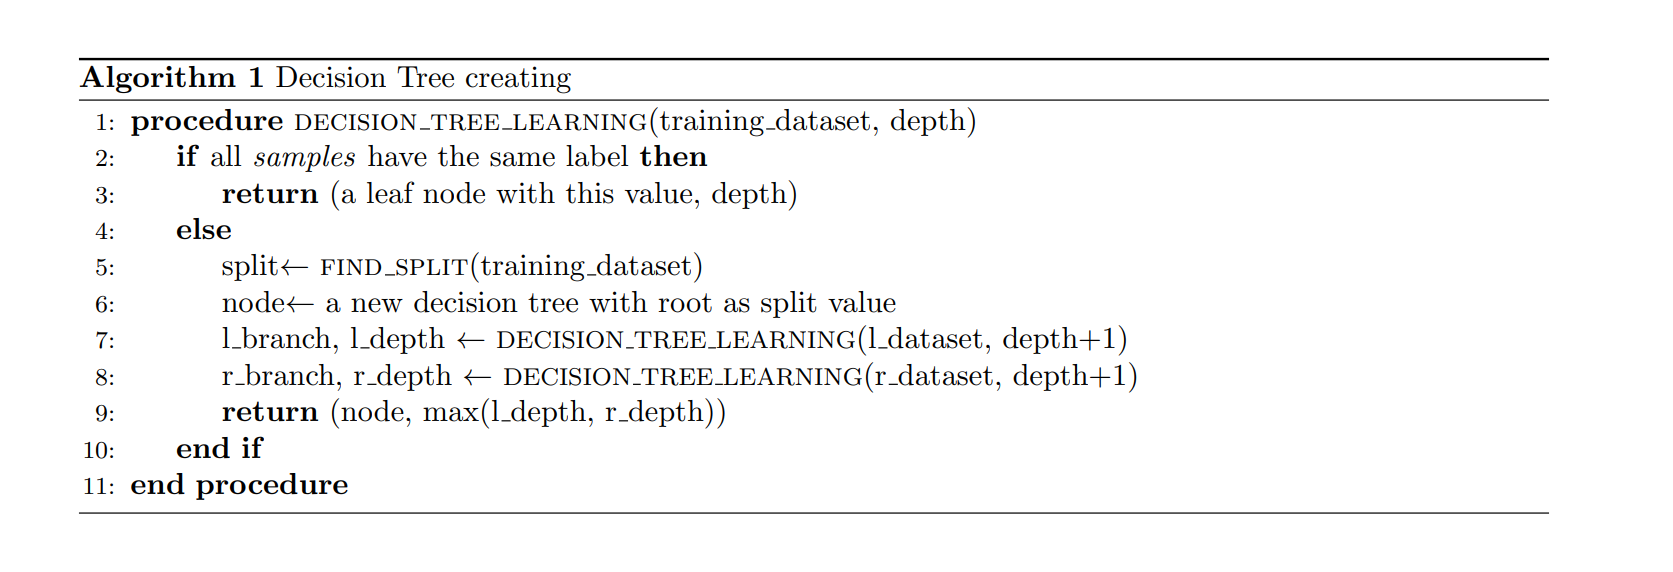

Psuedocode from *Artificial Intelligence: A Modern Approach* by Stuart Russell and Peter Norvig (Figure 18.5), but modified to
take into account that the considered dataset contains continuous attributes (see section 18.3.6 of the book).

In [2]:
def get_entropy(data):
    total = len(data)
    labels, counts = np.unique(data[:, -1], return_counts=True)
    entropy = 0
    for c in counts:
        entropy += -c/total * math.log2(c/total)
    return entropy

# Requires sorted data and the column the data was sorted on
def get_candidate_splits(sorted_data, col_sort):
    splits = []
    prev_val = None
    prev_label = None
    for d in sorted_data:
        # TODO: require a list of labels seperately so its more data agnostic
        if prev_val and prev_val != d[col_sort] and prev_label and prev_label != d[7]:
            mid = prev_val + ((d[col_sort] - prev_val) / 2)
            splits.append((mid, d[7]))
        prev_val = d[col_sort]
        prev_label = d[7]
    return splits

def find_split(data):
    '''
    - For each attribute order the values 
        - Find candidate split at decision boundaries
        - find split that gives us most IG
    - Repeat for each attribute and return the attr and split
    - resulting in the highest IG
    '''
    # Entropy for dataset
    h_data = get_entropy(data)
    # Last column is label
    no_attr = data.shape[1] - 1
    best_split = None
    for col in range(0, no_attr):
        sorted_data = data[data[:, col].argsort()]
        splits = get_candidate_splits(sorted_data, col)
        # Max information gain (split_point, Info Gain)
        max_ig = (-1, -1)
        for s in splits:
            filter_left = data[:, col] < s[0]
            filter_right = data[:, col] >= s[0]
    
            left_data = data[filter_left]
            right_data = data[filter_right]
            
            total_entropy = (len(left_data)/len(data)) * get_entropy(left_data) + (len(right_data)/len(data)) * get_entropy(right_data)
            max_ig = max(max_ig, (s[0], h_data - total_entropy), key= lambda x: x[1])
        if best_split and max_ig[1] > best_split[1][1]:
            best_split = (col, max_ig)
        if not best_split:
            best_split = (col, max_ig)
    return best_split


def decision_tree_learning(training_dataset, depth):
   
    
    labels, counts = np.unique(training_dataset[:, -1], return_counts=True)
    col, max_ig = find_split(training_dataset)
    if len(np.unique(labels)) == 1:
        node = {"attribute":"leaf", "value":labels[0], "left":"", "right":""}
        return (node, depth)
    # Edge case where we couldn't find an appropriate split candidate (due to noise)
    elif max_ig == (-1,-1):
        common = max(zip(labels,counts), key=lambda x: x[1])
        node = {"attribute":"leaf", "value":common[0], "left":"", "right":""}
        return (node, depth)
    else:
        val = max_ig[0]
        node = {"attribute":col, "value":val, "left":"", "right":""}
        filter_left = training_dataset[:, col] < val
        filter_right = training_dataset[:, col] >= val
        l_data = training_dataset[filter_left]
        r_data = training_dataset[filter_right]
        l_branch, l_depth = decision_tree_learning(l_data, depth+1)
        r_branch, r_depth = decision_tree_learning(r_data, depth+1)
        node["left"] = l_branch
        node["right"] = r_branch
        return (node, max(l_depth, r_depth))

tree = decision_tree_learning(train, 0)
print(tree)

({'attribute': 0, 'value': np.float64(-54.5), 'left': {'attribute': 4, 'value': np.float64(-59.5), 'left': {'attribute': 3, 'value': np.float64(-55.5), 'left': {'attribute': 4, 'value': np.float64(-64.5), 'left': {'attribute': 'leaf', 'value': np.float64(1.0), 'left': '', 'right': ''}, 'right': {'attribute': 6, 'value': np.float64(-85.5), 'left': {'attribute': 3, 'value': np.float64(-60.5), 'left': {'attribute': 4, 'value': np.float64(-62.0), 'left': {'attribute': 'leaf', 'value': np.float64(1.0), 'left': '', 'right': ''}, 'right': {'attribute': 'leaf', 'value': np.float64(4.0), 'left': '', 'right': ''}}, 'right': {'attribute': 1, 'value': np.float64(-53.0), 'left': {'attribute': 'leaf', 'value': np.float64(4.0), 'left': '', 'right': ''}, 'right': {'attribute': 'leaf', 'value': np.float64(3.0), 'left': '', 'right': ''}}}, 'right': {'attribute': 'leaf', 'value': np.float64(1.0), 'left': '', 'right': ''}}}, 'right': {'attribute': 0, 'value': np.float64(-57.5), 'left': {'attribute': 0, 'v

In [30]:
'''
            Pred 1, Pred 2, Pred 3, Pred 4   
Row actual 1  TP    
Row actual 2        TP
Row actual 3                 TP
Row actual 4                        TP
'''

def get_confusion_matrix(test_pred, test_real):
    conf_mat = np.zeros((4,4), int)
    pred_map = {}
    for i in range(0,len(test_real)):
        real = test_real[i]
        pred = test_pred[i]
        conf_mat[int(real-1), int(pred-1)] += 1
    return conf_mat
    
    
def get_accuracy(test_predictions, test_real):
    assert(test_predictions.shape == test_real.shape)
    correct = 0
    for i in range(len(test_predictions)):
        if test_predictions[i] == test_real[i]:
            correct += 1
    return correct/len(test_predictions)

    
def evaluate(test_data, tree):
    point = test_data[0]
    test_real = test_data[:, -1]
    test_predictions = []
    for point in test_data:
        node = tree[0]
        while node["attribute"] != "leaf":
            if point[node["attribute"]] < node["value"]:
                node = node["left"]
            else:
                node = node["right"]
        test_predictions.append(node["value"])
    test_predictions = np.array(test_predictions)
    conf_mat = get_confusion_matrix(test_predictions, test_real)
    print(conf_mat)
    return get_accuracy(test_predictions, test_real)



In [31]:
import matplotlib.pyplot as plt


def plot_tree(result, file_name="decision_tree"):
    tree, max_depth = result
    positions = {}
    leaf_count = 0
    leaf_colour = "springgreen"
    attribute_colour = "peru"

    # Calculate the positions of each node
    def calc_pos(node, depth=0, leaf_count=0):
        if node["attribute"] == "leaf":
            x = leaf_count
            leaf_count += 1
        else:
            left_x, leaf_count = calc_pos(node["left"], depth + 1, leaf_count)
            right_x, leaf_count = calc_pos(node["right"], depth + 1, leaf_count)
            x = (left_x + right_x) / 2
        positions[id(node)] = (x, -depth)
        return x, leaf_count

    _, leaf_count = calc_pos(tree)
    print(f"{leaf_count} Leaves")
    print(positions)
    fig, ax = plt.subplots(
        figsize=(leaf_count, max_depth)
    )

    # Draw the tree
    def draw(node):
        
        x, y = positions[id(node)]
        if node["attribute"] == "leaf":
            label = f"Class {int(node['value'])}"
            colour = leaf_colour
        else:
            label = f"X[{node['attribute']}] < {node['value']:.2f}"
            colour = attribute_colour
        ax.text(
            x, y, label,
            ha="center", va="center",
            fontsize=9,
            bbox=dict(
                facecolor=colour,
                edgecolor="black"
            ),
            zorder=2
        )
        # Draw all the arrows between the boxes
        if not node["attribute"] == "leaf":
            for decision, child in [
                ("Yes", node["left"]),
                ("No", node["right"])
            ]:
                child_x, child_y = positions[id(child)]
                ax.annotate(
                    "",
                    xy=(child_x, child_y),
                    xytext=(x, y),
                    arrowprops=dict(
                        arrowstyle="-",
                        color="black",
                    ),
                    zorder=1
                )
                ax.text(
                    (x + child_x) / 2,
                    (y + child_y) / 2,
                    decision,
                    ha="right"
                )
                draw(child)

    draw(tree)

    ax.set_xlim(-1, leaf_count)
    ax.set_ylim(-max_depth - 1, 1)
    ax.axis("off")

    plt.tight_layout()
    plt.savefig(file_name+".svg", bbox_inches="tight")
    plt.show()


[[100   0   0   0]
 [  0  93   7   0]
 [  0   7  93   0]
 [  0   0   2  98]]
47 Leaves
{127501256651776: (0, -4), 127501256641536: (1, -7), 127501256653760: (2, -7), 127501262115584: (1.5, -6), 127501256652288: (3, -7), 127501247123008: (4, -7), 127501256646528: (3.5, -6), 127501262114880: (2.5, -5), 127501247132352: (5, -5), 127501256652160: (3.75, -4), 127501068853696: (1.875, -3), 127501256650560: (6, -5), 127501256653568: (7, -5), 127502293527744: (6.5, -4), 127501256647232: (8, -4), 127501255765248: (7.25, -3), 127501259513856: (4.5625, -2), 127501256651072: (9, -4), 127501256644608: (10, -4), 127501256647744: (9.5, -3), 127501256651712: (11, -3), 127501256646848: (10.25, -2), 127501247129856: (7.40625, -1), 127501256649216: (12, -6), 127501256651264: (13, -7), 127501256645888: (14, -7), 127501256654464: (13.5, -6), 127501256640064: (12.75, -5), 127501256644544: (15, -7), 127501256653312: (16, -7), 127501256650112: (15.5, -6), 127501256649152: (17, -6), 127501256651200: (16.25, -5

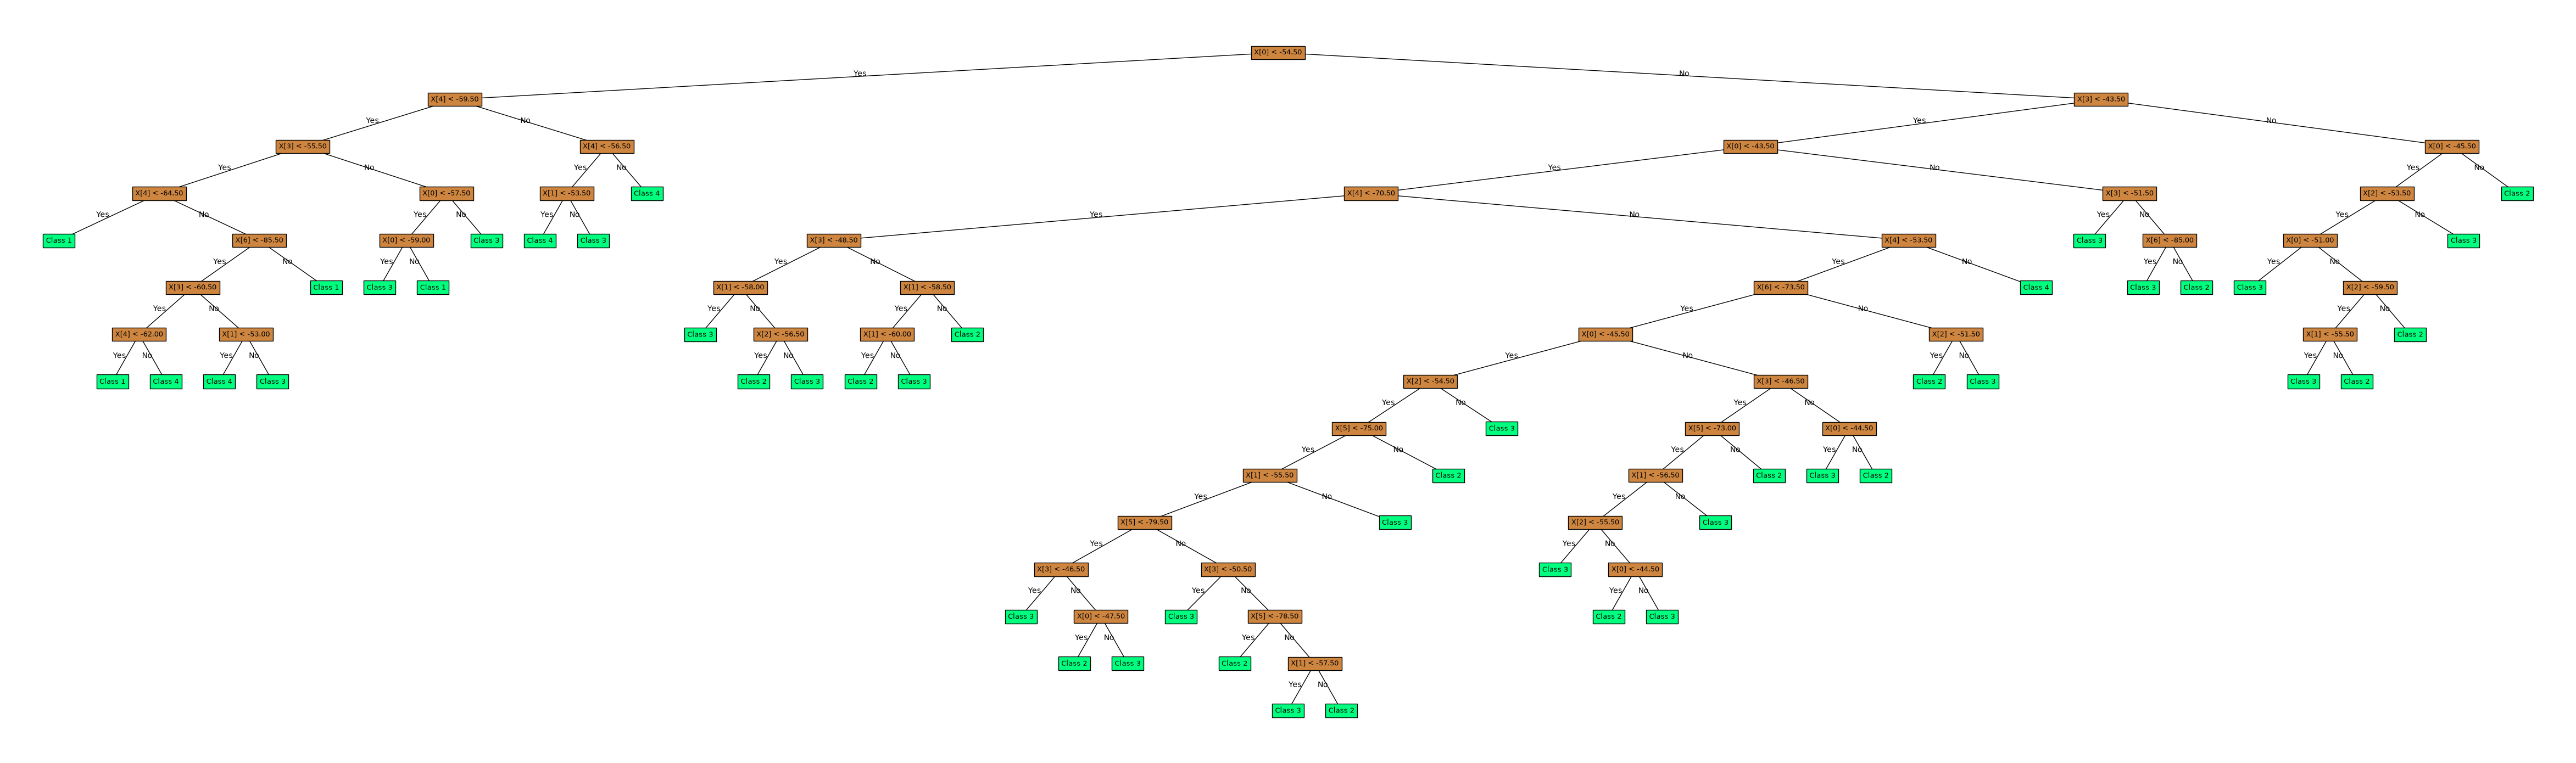

[[71  7 11  9]
 [ 6 74 10 10]
 [ 9  6 85  3]
 [ 5  5  7 83]]
281 Leaves
{127501251407936: (0, -10), 127501251405440: (1, -11), 127501251395840: (2, -11), 127501251404992: (1.5, -10), 127501251410816: (0.75, -9), 127501251406784: (3, -11), 127501251400576: (4, -11), 127501251405056: (3.5, -10), 127501251411776: (5, -11), 127501251411456: (6, -12), 127501251398080: (7, -12), 127501251407680: (6.5, -11), 127501251411712: (5.75, -10), 127501251399168: (4.625, -9), 127501251409536: (2.6875, -8), 127501258936192: (8, -8), 127501251396352: (5.34375, -7), 127501255766464: (9, -9), 127501249203968: (10, -9), 127501255767232: (9.5, -8), 127501255758016: (11, -8), 127501249207104: (10.25, -7), 127501251396096: (7.796875, -6), 127502293655296: (12, -9), 127501258868288: (13, -9), 127501258935232: (12.5, -8), 127501250681280: (14, -8), 127501250806976: (13.25, -7), 127501260343104: (15, -8), 127501260221184: (16, -10), 127501248867968: (17, -10), 127501259150400: (16.5, -9), 127501259905216: (18, -



Clean dataset accuracy: 96.0%
Noisy dataset accuracy: 78.05486284289277%


In [32]:
# Full pipeline

path = "wifi_db/clean_dataset.txt"
train, test = create_split_data(path, 0.8)
tree_clean = decision_tree_learning(train, 0)
accuracy_clean = evaluate(test, tree_clean)
plot_tree(tree_clean, "clean")

path = "wifi_db/noisy_dataset.txt"
train, test = create_split_data(path, 0.8)
tree_noisy = decision_tree_learning(train, 0)
accuracy_noisy = evaluate(test, tree_noisy)

plot_tree(tree_noisy, "noisy")

print(f"Clean dataset accuracy: {accuracy_clean*100}%")
print(f"Noisy dataset accuracy: {accuracy_noisy*100}%")